
# Desafio 1 — Análise de Crédito | CredAIR

## 1. Entendimento do problema

O objetivo deste projeto é investigar os fatores associados à inadimplência em propostas de crédito e desenvolver um modelo de classificação utilizando Regressão Logística.

A variável resposta é *`inadimplente`*, que indica se uma proposta resultou ou não em inadimplência.

O problema será tratado como aprendizado supervisionado de classificação binária, pois os dados históricos possuem a resposta conhecida para cada registro.




In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#%pip install seaborn
import seaborn as sns


### 2. Análise exploratória

In [2]:
df = pd.read_csv("dataset.csv")
df

,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
0,52,MS,Ensino Superior,2911.82,14,690,5934.19,60,Viagem,1,0
1,49,RR,Ensino Médio,3176.43,5,676,6791.38,24,Outros,2,0
2,48,AL,Ensino Superior,3429.40,23,558,14666.78,24,Outros,5,1
3,59,GO,Ensino Fundamental,10096.70,2,739,19053.24,24,Reforma,0,0
4,37,RJ,Ensino Fundamental,3033.25,24,797,6171.31,6,Educação,0,1
...,...,...,...,...,...,...,...,...,...,...,...
4995,31,PB,Ensino Médio,3374.04,8,677,10198.45,24,Outros,2,0
4996,64,AM,Ensino Superior,3638.91,20,643,15374.40,24,Reforma,1,0
4997,48,MT,Ensino Médio,2211.31,21,486,8236.10,48,Saúde,0,1
4998,19,AP,Ensino Superior,14709.61,4,766,10617.90,18,Veículo,1,0


### •Métricas dos dados

In [3]:
display(df.describe().T)#Transpose

,count,mean,std,min,25%,50%,75%,max
idade,5000.0,47.767400,31.646099,18.00,32.00,46.00,61.0000,750.00
renda_mensal,5000.0,5228.633582,3968.478198,100.00,2697.32,4146.30,6458.8775,44814.19
tempo_emprego_anos,5000.0,12.662200,7.517539,1.00,6.00,13.00,19.0000,74.00
score_credito,5000.0,652.481200,84.817076,335.00,594.00,653.00,710.0000,850.00
valor_solicitado,5000.0,14264.657378,8268.261465,1721.48,8467.17,12365.63,17764.8850,50000.00
prazo_meses,5000.0,29.922000,15.482515,6.00,18.00,24.00,36.0000,60.00
dividas_ativas,5000.0,1.900400,1.864719,0.00,0.00,1.00,3.0000,7.00
inadimplente,5000.0,0.344000,0.475089,0.00,0.00,0.00,1.0000,1.00


In [4]:
colunas = df.isnull().any()
print(colunas)

display(df.columns[colunas])

print("Valores ausentes por coluna:")
print(df.isna().sum())

print("\nQuantidade de linhas duplicadas:")
print(df.duplicated().sum())

idade                 False
estado                False
escolaridade          False
renda_mensal          False
tempo_emprego_anos    False
score_credito         False
valor_solicitado      False
prazo_meses           False
finalidade            False
dividas_ativas        False
inadimplente          False
dtype: bool


Index([], dtype='str')

Valores ausentes por coluna:
idade                 0
estado                0
escolaridade          0
renda_mensal          0
tempo_emprego_anos    0
score_credito         0
valor_solicitado      0
prazo_meses           0
finalidade            0
dividas_ativas        0
inadimplente          0
dtype: int64

Quantidade de linhas duplicadas:
19


### •Como nas métricas foram identificados Idades e Tempo de Emprego acima do comum, será feito novas análises 

In [5]:
print("Idades acima de 100:")
display(df[df["idade"] > 100])

print("Tempo de emprego acima de 40 anos:")
display(df[df["tempo_emprego_anos"] > 40])

print("Quantidade de estados distintos:")
print(df["estado"].nunique())

print("Estados distintos:")
print(sorted(df["estado"].unique()))

Idades acima de 100:


,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
482,660,CE,Ensino Superior,8737.57,7,626,11238.42,24,Saúde,1,0
697,680,RN,Ensino Médio,12067.28,20,535,8190.12,12,Educação,1,0
925,710,RS,Ensino Superior,2785.13,15,658,31054.95,18,Educação,0,0
975,430,TO,Ensino Superior,1883.08,10,598,21313.88,12,Veículo,4,1
987,300,SC,Ensino Médio,4748.00,19,655,10309.08,36,Viagem,0,0
1220,360,AC,Ensino Médio,4863.25,4,764,7974.62,18,Viagem,0,0
1263,440,DF,Ensino Superior,4330.45,18,542,34623.38,48,Educação,2,1
1290,280,RS,Ensino Médio,4146.73,5,534,23719.54,6,Reforma,0,1
1507,500,MT,Ensino Superior,2493.59,2,758,15382.55,18,Educação,0,0
2671,340,SC,Ensino Médio,12069.75,8,683,11191.93,48,Reforma,4,0


Tempo de emprego acima de 40 anos:


,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
388,56,RR,Ensino Médio,16193.38,57,617,7028.37,48,Reforma,0,0
850,62,PA,Ensino Fundamental,3741.96,63,730,12445.89,6,Veículo,1,1
1937,73,DF,Ensino Fundamental,2609.94,74,721,13972.16,36,Reforma,0,0
2659,45,RJ,Ensino Superior,2797.80,46,690,7981.42,48,Outros,1,0
2711,56,BA,Ensino Médio,2109.55,57,598,19541.27,36,Reforma,1,1
3162,64,MS,Ensino Médio,1996.15,65,597,15080.16,24,Veículo,1,0
4655,66,SP,Ensino Médio,2391.84,67,718,19779.15,24,Outros,2,1


Quantidade de estados distintos:
85
Estados distintos:
['  AC ', '  AL ', '  AL  ', '  AM ', '  CE ', '  DF ', '  GO ', '  MG ', '  MS ', '  PA ', '  PB ', '  PB  ', '  PE  ', '  PI ', '  RO  ', '  RR ', '  RR  ', '  RS ', '  RS  ', '  SE ', '  SE  ', '  SP ', '  SP  ', ' AC  ', ' AL ', ' AM ', ' AM  ', ' AP  ', ' BA ', ' CE ', ' DF ', ' ES ', ' GO ', ' GO  ', ' MA ', ' MG ', ' MG  ', ' MS ', ' MT  ', ' PA ', ' PB ', ' PB  ', ' PE ', ' PE  ', ' PI ', ' PI  ', ' RJ ', ' RJ  ', ' RN ', ' RN  ', ' RO ', ' RR ', ' RR  ', ' SC ', ' SC  ', ' SE ', ' SE  ', ' TO ', 'AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']


### •Também foi identificado a coluna Estado com mais Estados do que deveria, será filtrado para analisar

In [6]:
print("Estados com espaços extras:")

display(
    df.loc[
        df["estado"] != df["estado"].str.strip(),
        ["estado"]
    ].drop_duplicates()
    .sort_values("estado")
)

Estados com espaços extras:


,estado
510,AC
4010,AL
1136,AL
3226,AM
239,CE
1587,DF
1214,GO
2168,MG
459,MS
2941,PA


### •Verificar a variável resposta

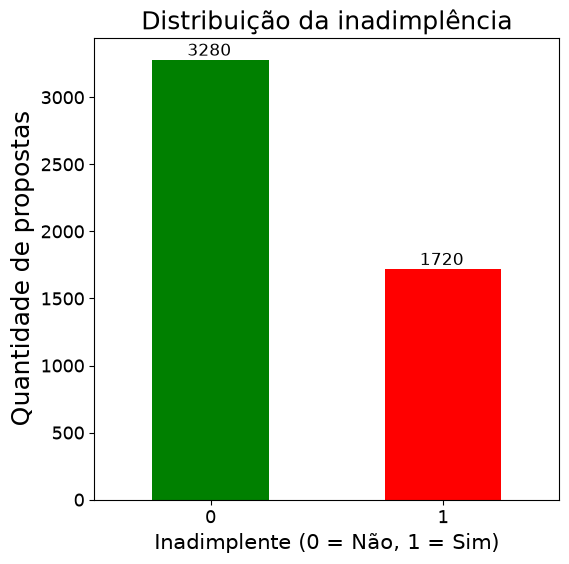

In [7]:
inadimplente = df["inadimplente"].value_counts()

grf = inadimplente.plot(
    kind='bar',
    rot=0, 
    figsize=(6,6),
    color=["green", "red"],#cores das barras
    fontsize=13,
    label='inadimplente'
    )

for i in grf.patches:
    grf.text(
        i.get_x() + 0.15, #0.15 é para colocar o valor mais no centro da barra
        i.get_height()+30,#+30 é para colocar o valor mais acima da barra
        i.get_height(), 
        color='black',
        fontsize=12
    )
grf.tick_params(axis="both", colors="black")#deixar valores de X e Y pretos

plt.style.use('ggplot')
plt.title("Distribuição da inadimplência", fontsize=18, color='black')
plt.xlabel("Inadimplente (0 = Não, 1 = Sim)", fontsize=15, color='black')
plt.ylabel("Quantidade de propostas", fontsize=18, color='black')
plt.show()

### •Dividir os Scores em faixas para análise.

In [8]:
faixas_score = pd.cut(
    df["score_credito"],
    bins=[0, 500, 600, 700, 800, 1000],
    right=False
)

taxa_score = (
    df.groupby(faixas_score, observed=False)["inadimplente"]
      .agg(["count", "mean"])
)

taxa_score["mean"] = taxa_score["mean"] * 100

display(taxa_score.rename(columns={
    "count": "quantidade",
    "mean": "taxa_inadimplencia_%"
}))

,quantidade,taxa_inadimplencia_%
score_credito,,
"[0, 500)",188,63.829787
"[500, 600)",1163,51.590714
"[600, 700)",2174,34.222631
"[700, 800)",1255,18.486056
"[800, 1000)",220,10.909091


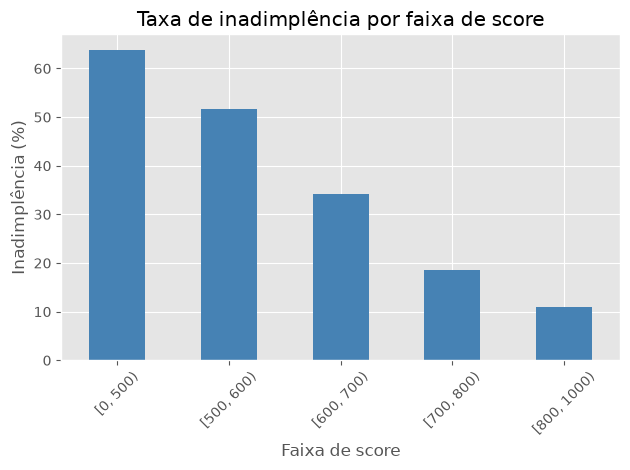

In [9]:
taxa_score["mean"].plot(kind="bar", color="steelblue")

plt.title("Taxa de inadimplência por faixa de score")
plt.xlabel("Faixa de score")
plt.ylabel("Inadimplência (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### -Em uma analise Rápida, da pra ver que quanto menor o Score, maior a taxa de inadimplência.

## •Taxa de inadimplência por quantidade de dívidas

In [10]:
# Taxa de inadimplência por quantidade de dívidas

taxa_dividas = (
    df.groupby("dividas_ativas")["inadimplente"]
      .agg(["count", "mean"])
      .rename(columns={
          "count": "quantidade",
          "mean": "taxa_inadimplencia"
      })
)

taxa_dividas["taxa_inadimplencia"] *= 100

display(taxa_dividas.round(2))

# Estatísticas financeiras por classe
display(
    df.groupby("inadimplente")[
        ["renda_mensal", "valor_solicitado", "prazo_meses"]
    ].mean().round(2)
)

,quantidade,taxa_inadimplencia
dividas_ativas,,
0,1554,27.41
1,965,26.84
2,848,36.32
3,631,38.67
4,420,46.19
5,322,45.65
6,162,51.23
7,98,60.20


,renda_mensal,valor_solicitado,prazo_meses
inadimplente,,,
0,5770.95,13404.56,31.05
1,4194.45,15904.85,27.77


### -També é possível observar que quanto maior as dívidas maior a taxa de inadimplência.

## •Análises aprofundadas

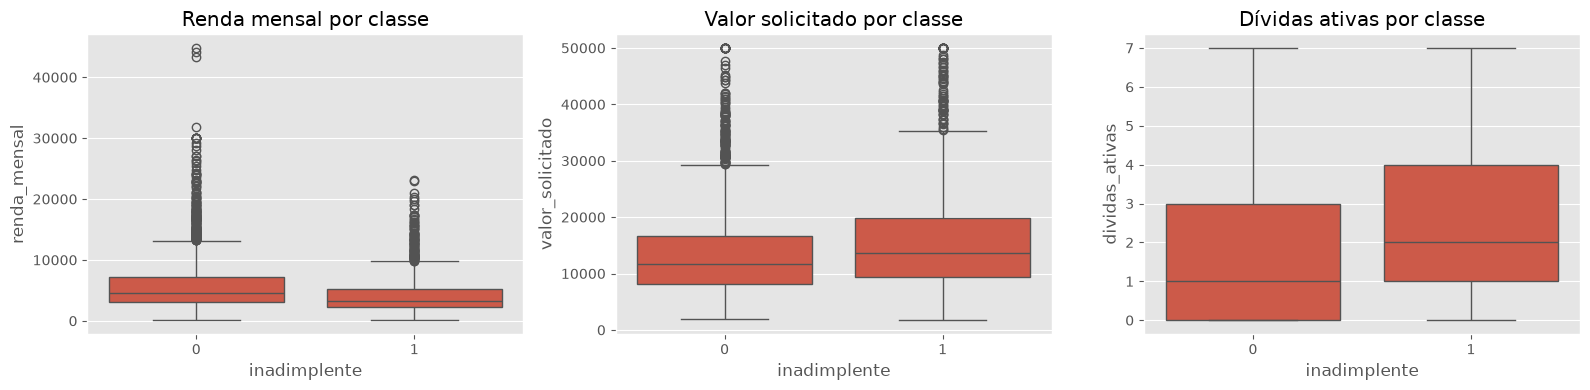

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(data=df, x="inadimplente", y="renda_mensal", ax=axes[0])
axes[0].set_title("Renda mensal por classe")

sns.boxplot(data=df, x="inadimplente", y="valor_solicitado", ax=axes[1])
axes[1].set_title("Valor solicitado por classe")

sns.boxplot(data=df, x="inadimplente", y="dividas_ativas", ax=axes[2])
axes[2].set_title("Dívidas ativas por classe")

# sns.boxplot(data=df, x="inadimplente", y="idade", ax=axes[3])
# axes[3].set_title("Dívidas ativas por Idade")

plt.tight_layout()
plt.show()

### Análise das distribuições por classe

Os boxplots indicam diferenças nas distribuições de renda mensal, valor solicitado e quantidade de dívidas ativas entre as classes de inadimplência. Os solicitantes inadimplentes aparentam apresentar menor renda mediana, maior valor mediano de empréstimo solicitado e maior quantidade mediana de dívidas ativas. Também foram observadas diversas observações potencialmente atípicas nas variáveis financeiras. Esses resultados são exploratórios e sugerem associações que deverão ser investigadas nas próximas etapas, sem permitir conclusões causais.

### •Criação de faixas de renda mensal 

In [12]:
df["faixa_renda"] = pd.cut(
    df["renda_mensal"],
    bins=[0, 2000, 4000, 6000, 10000, float("inf")],
    labels=[
        "Até 2 mil",
        "2 a 4 mil",
        "4 a 6 mil",
        "6 a 10 mil",
        "Acima de 10 mil"
    ]
)

taxa_renda = (
    df.groupby("faixa_renda", observed=False)["inadimplente"]
      .agg(["count", "mean"])
      .rename(columns={
          "count": "quantidade",
          "mean": "taxa_inadimplencia"
      })
)

taxa_renda["taxa_inadimplencia"] *= 100

display(taxa_renda.round(2))

,quantidade,taxa_inadimplencia
faixa_renda,,
Até 2 mil,639,54.62
2 a 4 mil,1766,40.15
4 a 6 mil,1188,28.96
6 a 10 mil,924,24.46
Acima de 10 mil,483,19.05


### Análise da inadimplência por dívidas ativas e renda

A análise da taxa de inadimplência por quantidade de dívidas ativas revelou uma tendência geral de aumento da inadimplência em grupos com maior número de dívidas. A taxa variou de 26,84% entre solicitantes com uma dívida para 60,20% entre aqueles com sete dívidas ativas.

Em relação à renda mensal, observou-se uma associação inversa entre a faixa de renda e a taxa de inadimplência. O grupo com renda de até R$ 2.000 apresentou taxa de 54,62%, enquanto o grupo com renda superior a R$ 10.000 apresentou taxa de 19,05%.

Esses resultados sugerem que a quantidade de dívidas ativas e a renda mensal são variáveis relevantes para investigar o risco de inadimplência. Entretanto, as associações observadas não demonstram causalidade e deverão ser avaliadas em conjunto com as demais variáveis e com os resultados do modelo preditivo.


## 3. Limpeza e preparação dos dados

Nesta etapa, serão investigadas e tratadas inconsistências nos dados, incluindo espaços extras nas variáveis categóricas, registros duplicados e valores inválidos.



In [13]:
# Recarregar o arquivo original para evitar alterações
# feitas durante a análise exploratória
df = pd.read_csv("dataset.csv")

# Padronizar espaços nas colunas de texto
colunas_texto = df.select_dtypes(include="object").columns

for coluna in colunas_texto:
    df[coluna] = df[coluna].str.strip()

# Verificar duplicidades exatas
print("Duplicidades:", df.duplicated().sum())

# Remover registros duplicados
df = df.drop_duplicates().copy()

print("Dimensões após remoção:", df.shape)

Duplicidades: 19
Dimensões após remoção: (4981, 11)


C:\Users\Diniz\AppData\Local\Temp\ipykernel_22184\3735001894.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colunas_texto = df.select_dtypes(include="object").columns


### •Verificação dos tratamentos

In [14]:
# Idades fora de uma faixa plausível
df.loc[
    (df["idade"] < 18) | (df["idade"] > 100),
    "idade"
] = np.nan

# Tempo de emprego inválido
df.loc[
    (df["tempo_emprego_anos"] < 0) |
    (df["tempo_emprego_anos"] > df["idade"]),
    "tempo_emprego_anos"
] = np.nan

# Verificar o resultado
display(df[["idade", "tempo_emprego_anos"]].describe())
print(df[["idade", "tempo_emprego_anos"]].isna().sum())

,idade,tempo_emprego_anos
count,4966.000000,4973.000000
mean,46.408377,12.588377
std,16.786857,7.287819
min,18.000000,1.000000
25%,32.000000,6.000000
50%,46.000000,13.000000
75%,61.000000,19.000000
max,75.000000,25.000000


idade                 15
tempo_emprego_anos     8
dtype: int64


In [18]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Preparação das variáveis numéricas
preparo_numerico = Pipeline([
    ("imputacao", SimpleImputer(strategy="median")),
    ("escala", StandardScaler())
])

# Preparação das variáveis categóricas
preparo_categorico = Pipeline([
    ("imputacao", SimpleImputer(strategy="most_frequent")),
    ("codificacao", OneHotEncoder(handle_unknown="ignore"))
])


Nesta etapa, foi realizada a análise da qualidade dos dados da base CredAIR, com o objetivo de identificar e tratar problemas que poderiam prejudicar o treinamento dos modelos de Machine Learning.

**Principais verificações e tratamentos realizados:**

- `Valores ausentes:` foi verificada a existência de valores ausentes. Para o treinamento, foi configurada a imputação pela mediana nas variáveis numéricas e pela categoria mais frequente nas variáveis categóricas, utilizando SimpleImputer.

- `Inconsistências em textos:` foi aplicado o método str.strip() nas colunas textuais para remover espaços em branco no início e no final dos valores, corrigindo inconsistências como as encontradas na coluna estado.

- `Duplicidades:` foram identificadas 19 linhas duplicadas e realizada a remoção dos registros duplicados para evitar a repetição exata de observações.

- `Valores inválidos:` foram identificadas idades acima de 100 anos e registros em que o tempo de emprego era superior à idade do cliente. Esses valores foram tratados como ausentes para que pudessem ser tratados pelo processo de imputação. Também foram tratados valores de renda mensal menores ou iguais a zero.

### 4. Engenharia de atributos

### •Criação da variável derivada

In [19]:
# Evitar divisão por zero ou renda inválida
df.loc[df["renda_mensal"] <= 0, "renda_mensal"] = np.nan

df["proporcao_emprestimo_renda_anual"] = (
    df["valor_solicitado"] /
    (df["renda_mensal"] * 12)
)

Nesta etapa, foi criada uma variável derivada com o objetivo de representar a relação entre o valor solicitado pelo cliente e sua renda anual estimada.

**Variável criada: proporcao_emprestimo_renda_anual**

- `Como foi construída:`
A variável foi calculada dividindo o valor solicitado pela renda mensal multiplicada por 12:
proporcao_emprestimo_renda_anual = valor_solicitado / (renda_mensal * 12)

- `O que representa:`
Essa variável indica a proporção do valor solicitado em relação à renda anual estimada do cliente. Por exemplo, um valor de 0,5 significa que o empréstimo solicitado equivale a 50% da renda anual estimada.

- `Justificativa:`
A relação entre o valor solicitado e a renda pode estar associada à capacidade de pagamento. Um empréstimo elevado em relação à renda anual pode representar um compromisso financeiro maior para o cliente e, potencialmente, estar relacionado a um risco de inadimplência mais elevado. Essa relação deve ser investigada nos dados, pois não representa, isoladamente, a capacidade real de pagamento.

- `Utilização no modelo:`
A variável será incluída entre as features candidatas ao treinamento dos modelos. Sua contribuição deve ser avaliada por meio dos resultados do modelo, mantendo uma metodologia de validação consistente.

In [20]:
df.head()

,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente,proporcao_emprestimo_renda_anual
0,52.0,MS,Ensino Superior,2911.82,14.0,690,5934.19,60,Viagem,1,0,0.169830
1,49.0,RR,Ensino Médio,3176.43,5.0,676,6791.38,24,Outros,2,0,0.178171
2,48.0,AL,Ensino Superior,3429.40,23.0,558,14666.78,24,Outros,5,1,0.356398
3,59.0,GO,Ensino Fundamental,10096.70,2.0,739,19053.24,24,Reforma,0,0,0.157256
4,37.0,RJ,Ensino Fundamental,3033.25,24.0,797,6171.31,6,Educação,0,1,0.169546


### 5. Preparação para modelagem

Nesta etapa, os dados foram organizados para serem utilizados nos algoritmos de Machine Learning, definindo as variáveis explicativas, a variável-alvo e os procedimentos de transformação necessários para o treinamento.

**Procedimentos realizados:**

- **Definição das features (`X`):** foram selecionadas as variáveis utilizadas como entradas dos modelos, incluindo a variável derivada criada na etapa 4, desde que presente na base utilizada para a modelagem.
- **Definição do target (`y`):** foi selecionada a coluna `inadimplente`, que representa a variável que o modelo deve prever.
- **Divisão dos dados:** a base foi dividida em conjuntos de treino e teste, utilizando `train_test_split` e estratificação pela variável-alvo para preservar a proporção das classes.
- **Separação por tipo:** as variáveis foram identificadas como numéricas ou categóricas, permitindo aplicar transformações específicas a cada grupo.
- **Imputação:** foi configurado o `SimpleImputer`, utilizando a mediana para variáveis numéricas e a categoria mais frequente para variáveis categóricas.
- **Padronização:** foi utilizado o `StandardScaler` para padronizar as variáveis numéricas, procedimento especialmente relevante para a Regressão Logística.
- **Codificação:** foi utilizado o `OneHotEncoder` para converter as variáveis categóricas em representações numéricas.

- **Separação:** foi separado `80%` dos dados para treinamento e `20%` para teste.

O pré-processamento foi organizado com `Pipeline` e `ColumnTransformer`, permitindo aplicar as transformações de forma consistente durante o treinamento e aprender os parâmetros de transformação apenas com os dados de treino.

**Justificativa:** a preparação permite que os algoritmos recebam os dados em um formato adequado, reduzindo problemas relacionados a escalas diferentes, valores ausentes e variáveis categóricas. A aplicação das transformações dentro do pipeline também ajuda a evitar vazamento de informações do conjunto de teste.

**Resultado:** foram definidos os conjuntos de treino e teste e estruturado o processo de transformação dos dados para utilização nos modelos de Machine Learning.

In [21]:
#%pip install scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

### •Separar a variável resposta das variáveis explicativas

In [22]:

X = df.drop(columns=["inadimplente"])
y = df["inadimplente"]

# Identificar os tipos de variáveis
colunas_numericas = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

colunas_categoricas = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Variáveis numéricas:", colunas_numericas)
print("Variáveis categóricas:", colunas_categoricas)

Variáveis numéricas: ['idade', 'renda_mensal', 'tempo_emprego_anos', 'score_credito', 'valor_solicitado', 'prazo_meses', 'dividas_ativas', 'proporcao_emprestimo_renda_anual']
Variáveis categóricas: ['estado', 'escolaridade', 'finalidade']


C:\Users\Diniz\AppData\Local\Temp\ipykernel_22184\1342536844.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colunas_categoricas = X.select_dtypes(


### •Separação dados de treinamento e teste

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

Treino: (3984, 11)
Teste: (997, 11)


### •Preparação das variáveis Categóricas e Numéricas

### 6. Modelagem

## Etapa 6 — Desenvolvimento dos modelos de Machine Learning

Nesta etapa, foram desenvolvidos modelos de classificação para estimar a probabilidade de inadimplência das propostas de crédito da base CredAIR. Foi utilizada inicialmente a Regressão Logística e, posteriormente, o Random Forest, permitindo comparar abordagens distintas para o problema.

### 1. Regressão Logística

**Modelo utilizado:** `LogisticRegression`

**Procedimentos realizados:**

- **Definição do algoritmo:** foi escolhida a Regressão Logística, um algoritmo de classificação binária adequado para estimar a probabilidade de ocorrência de um evento, neste caso, a inadimplência.
- **Integração com o pré-processamento:** o modelo foi organizado em um `Pipeline`, combinando as transformações definidas na etapa 5 com o classificador.
- **Treinamento:** o modelo foi treinado com `X_train` e `y_train`, utilizando os dados de treino para aprender a relação entre as variáveis explicativas e a variável-alvo.
- **Geração de previsões:** após o treinamento, foram realizadas previsões com `X_test` para avaliar o desempenho do modelo em dados separados durante a divisão da base.

**Justificativa:** a Regressão Logística foi utilizada como modelo inicial por ser um método tradicional de classificação binária, permitir a estimativa de probabilidades e oferecer possibilidades de interpretação da relação entre as variáveis explicativas e o resultado previsto.





In [30]:
# Aplicar a preparação correta para cada tipo de variável
preparo = ColumnTransformer([
    ("num", preparo_numerico, colunas_numericas),
    ("cat", preparo_categorico, colunas_categoricas)
])

# Pipeline completo: preparação + modelo
modelo = Pipeline([
    ("preparo", preparo),
    ("classificador", LogisticRegression(max_iter=1000))
])

# Treinar
modelo.fit(X_train, y_train)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [31]:
# Previsões de classe
y_pred = modelo.predict(X_test)

# Probabilidade estimada de inadimplência
y_prob = modelo.predict_proba(X_test)[:, 1]

print("Acurácia:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred))

print("\nMatriz de confusão:")
print(confusion_matrix(y_test, y_pred))

Acurácia: 0.7332
ROC-AUC: 0.7657

Relatório de classificação:


              precision    recall  f1-score   support

           0       0.76      0.88      0.81       654
           1       0.66      0.46      0.54       343

    accuracy                           0.73       997
   macro avg       0.71      0.67      0.68       997
weighted avg       0.72      0.73      0.72       997


Matriz de confusão:
[[574  80]
 [186 157]]


## 1. Primeiro resultado — Regressão Logística
No primeiro modelo, usamos o limiar padrão de 0.5.

Os resultados registrados foram:

**Métrica	Classe inadimplente (1)**
- Precisão (precision):	66%
- Revocação (recall):	46%
- F1-score	0,54:
- Acurácia geral: 73,32%
- ROC-AUC: 76%

A matriz de confusão foi [[574, 80], [186, 157]]. Isso significa que o modelo identificou corretamente 574 clientes adimplentes, mas deixou passar 80 casos de bons pagadores(falso positivo), também identificou corretamente 157 clientes inadimplentes, mas deixou passar 186 casos de inadimplência(falsos negativos).

**O ponto principal:** a acurácia de 73,32% parecia razoável, mas o modelo identificava menos da metade dos inadimplentes reais. Como o objetivo é avaliar o risco de crédito, precisamos investigar se será possível aumentar essa capacidade de identificação.

### •Por isso será realizado testes de threshold na Regressão Logística, para verificar os resultados com diferentes parâmetros de probabilidade

In [32]:
# Probabilidade prevista de inadimplência (classe 1)
probabilidades = modelo.predict_proba(X_test)[:, 1]

# Testar diferentes thresholds
for threshold in [0.3, 0.4, 0.5, 0.6]:
    previsoes = (probabilidades >= threshold).astype(int)



    print(f"\n{'=' * 60}")
    print(f"THRESHOLD: {threshold}")
    print("Acurácia:", round(accuracy_score(y_test, previsoes), 4))
    print("ROC-AUC:", round(roc_auc_score(y_test, probabilidades), 4))    
    print(classification_report(y_test, previsoes, zero_division=0))
    print("Matriz de confusão:")
    print(confusion_matrix(y_test, previsoes))


THRESHOLD: 0.3
Acurácia: 0.6841
ROC-AUC: 0.7657
              precision    recall  f1-score   support

           0       0.82      0.66      0.73       654
           1       0.53      0.73      0.61       343

    accuracy                           0.68       997
   macro avg       0.68      0.69      0.67       997
weighted avg       0.72      0.68      0.69       997

Matriz de confusão:
[[432 222]
 [ 93 250]]

THRESHOLD: 0.4
Acurácia: 0.7292
ROC-AUC: 0.7657
              precision    recall  f1-score   support

           0       0.80      0.79      0.79       654
           1       0.61      0.61      0.61       343

    accuracy                           0.73       997
   macro avg       0.70      0.70      0.70       997
weighted avg       0.73      0.73      0.73       997

Matriz de confusão:
[[517 137]
 [133 210]]

THRESHOLD: 0.5
Acurácia: 0.7332
ROC-AUC: 0.7657
              precision    recall  f1-score   support

           0       0.76      0.88      0.81       654
    

Análise dos diferentes limiares de classificação

Após avaliar o resultado inicial, foram testados diferentes valores de threshold: 0,3, 0,4, 0,5 e 0,6. O objetivo foi compreender como a alteração do limiar utilizado para classificar uma proposta como inadimplente afeta o desempenho do modelo.

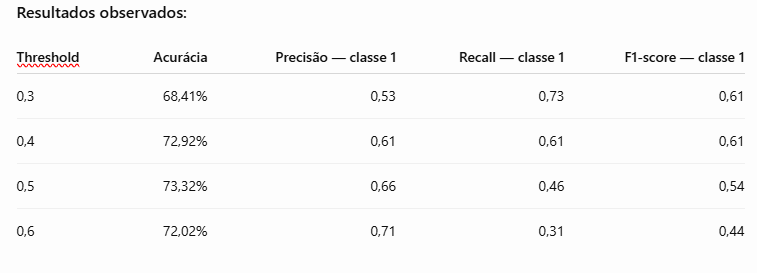

## Interpretação:

`Com o threshold de 0,3`, o recall da classe inadimplente aumentou para 73%, indicando que o modelo passou a identificar uma parcela maior dos clientes que realmente apresentaram inadimplência. ***Entretanto, a precisão diminuiu e a quantidade de falsos positivos aumentou.***

`Com o threshold de 0,4`, houve um equilíbrio entre precisão e recall, ambos próximos de 61%. 

`Já com os limiares de 0,5 e 0,6`, o modelo apresentou maior precisão. ***Mas deixou de identificar uma parcela maior dos inadimplentes reais.***

**Conclusão:** a redução do threshold favoreceu a identificação de inadimplentes, mas aumentou o risco de classificar clientes adimplentes incorretamente. A escolha do limiar depende do equilíbrio desejado entre identificar possíveis inadimplentes e evitar falsas sinalizações de risco.

O ROC-AUC deve ser calculado a partir das probabilidades previstas pelo modelo, e não das classificações binárias obtidas após a aplicação do threshold. Por isso, essa métrica foi corrigida para utilizar as probabilidades, permitindo avaliar a capacidade de discriminação do modelo independentemente do limiar escolhido.

### 2. Random Forest

**Modelo utilizado:** `RandomForestClassifier`

**Procedimentos realizados:**

- **Definição do algoritmo:** foi utilizado o Random Forest, um algoritmo baseado na combinação de várias árvores de decisão, capaz de representar relações não lineares e interações entre variáveis.
- **Integração com o pré-processamento:** o modelo foi organizado em um `Pipeline`, reutilizando as transformações definidas na etapa 5.
- **Treinamento inicial:** foi treinado um modelo com 200 árvores (`n_estimators=200`), `random_state=42` e `class_weight="balanced"`, para considerar o desequilíbrio entre as classes.
- **Ajuste do modelo:** posteriormente, foram definidos `max_depth=8` e `min_samples_leaf=10`, buscando limitar a complexidade das árvores e melhorar a capacidade de generalização.
- **Geração de previsões:** foram obtidas previsões de classe e probabilidades de inadimplência para o conjunto de teste, permitindo avaliar e comparar os resultados.

**Justificativa:** o Random Forest foi utilizado como uma abordagem complementar à Regressão Logística, por conseguir capturar relações mais complexas entre as características dos clientes e a ocorrência de inadimplência.

In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Pipeline: preparação dos dados + Random Forest
modelo_rf = Pipeline([
    ("preparo", preparo),
    ("classificador", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# Treinar o modelo
modelo_rf.fit(X_train, y_train)

# Fazer previsões
previsoes_rf = modelo_rf.predict(X_test)
probabilidades_rf = modelo_rf.predict_proba(X_test)[:, 1]

# Avaliar o resultado
print("Acurácia:", round(accuracy_score(y_test, previsoes_rf), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, probabilidades_rf), 4))

print("\nRelatório de classificação:")
print(classification_report(y_test, previsoes_rf, zero_division=0))

print("Matriz de confusão:")
print(confusion_matrix(y_test, previsoes_rf))

Acurácia: 0.7282
ROC-AUC: 0.7616

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.78      0.81      0.80       654
           1       0.61      0.57      0.59       343

    accuracy                           0.73       997
   macro avg       0.70      0.69      0.69       997
weighted avg       0.72      0.73      0.73       997

Matriz de confusão:
[[530 124]
 [147 196]]


## 3. Utilização do Random Forest
### Desenvolvimento do modelo Random Forest

Após os testes com a Regressão Logística, foi desenvolvido um modelo Random Forest para comparar seu desempenho com o modelo inicial.

O Random Forest combina várias árvores de decisão e consegue representar relações não lineares e interações entre as variáveis, oferecendo uma abordagem complementar à Regressão Logística.

**Configuração inicial:** foram utilizadas 200 árvores, com `random_state=42` e `class_weight="balanced"` para considerar a diferença na quantidade de registros entre as classes.

**Resultados obtidos:**

- Acurácia: 72,82%.
- Precisão da classe inadimplente: aproximadamente 61%.
- Recall da classe inadimplente: 57,14%.
- F1-score da classe inadimplente: 0,59.
- ROC-AUC: 0,7616.

**Comparação com a Regressão Logística inicial:**

A Regressão Logística apresentou acurácia de 73,32%, enquanto o Random Forest obteve 72,82%. Entretanto, o Random Forest identificou uma parcela maior dos inadimplentes reais, com recall de 57,14%, contra aproximadamente 45,77% da Regressão Logística.

O Random Forest também apresentou menos falsos negativos: 147, em comparação com 186 na Regressão Logística. Por outro lado, gerou mais falsos positivos: 124, contra 80 no modelo inicial.

**Conclusão:** `embora a acurácia do Random Forest tenha sido ligeiramente inferior, sua capacidade de identificar inadimplentes foi superior. Esse resultado justifica a realização de ajustes nos parâmetros do modelo para investigar se seria possível melhorar ainda mais seu desempenho.`

In [34]:
modelo_rf_ajustado = Pipeline([
    ("preparo", preparo),
    ("classificador", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        max_depth=8,
        min_samples_leaf=10
    ))
])

modelo_rf_ajustado.fit(X_train, y_train)

previsoes_rf_ajustado = modelo_rf_ajustado.predict(X_test)
probabilidades_rf_ajustado = modelo_rf_ajustado.predict_proba(X_test)[:, 1]

print("Acurácia:",round(accuracy_score(y_test, previsoes_rf_ajustado), 4))

print("ROC-AUC:",round(roc_auc_score(y_test, probabilidades_rf_ajustado), 4))

print("\nRelatório de classificação:")
print(classification_report(
    y_test, previsoes_rf_ajustado, zero_division=0
))

print("Matriz de confusão:")
print(confusion_matrix(y_test, previsoes_rf_ajustado))

Acurácia: 0.7091
ROC-AUC: 0.7743

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.81      0.73      0.77       654
           1       0.57      0.66      0.61       343

    accuracy                           0.71       997
   macro avg       0.69      0.70      0.69       997
weighted avg       0.72      0.71      0.71       997

Matriz de confusão:
[[479 175]
 [115 228]]


## 4. Ajuste do Random Forest
### Ajuste dos parâmetros do Random Forest

Após avaliar o modelo inicial, foram realizados ajustes nos parâmetros do Random Forest com o objetivo de controlar a complexidade das árvores e melhorar a capacidade de generalização.

**Parâmetros ajustados:**

- `n_estimators=200`: manutenção de 200 árvores na composição do modelo.
- `max_depth=8`: limitação da profundidade máxima das árvores.
- `min_samples_leaf=10`: exigência de pelo menos 10 amostras em cada folha.
- `class_weight="balanced"`: manutenção dos pesos das classes para considerar o desequilíbrio da variável-alvo.

**Resultados obtidos após o ajuste:**

- Acurácia: 70,91%.
- Precisão da classe inadimplente: aproximadamente 57%.
- Recall da classe inadimplente: 66,47%.
- F1-score da classe inadimplente: 0,61.
- ROC-AUC: 0,7743.

A matriz de confusão apresentou 228 verdadeiros positivos, 115 falsos negativos e 175 falsos positivos.

**Interpretação dos resultados:**

Em comparação com o Random Forest inicial, o modelo ajustado aumentou o recall da classe inadimplente de 57,14% para 66,47%, reduzindo os falsos negativos de 147 para 115. Isso significa que passou a identificar uma parcela maior dos clientes inadimplentes.

Por outro lado, a acurácia diminuiu de 72,82% para 70,91%, e a precisão da classe inadimplente caiu de aproximadamente 61% para 57%. Além disso, houve aumento dos falsos positivos, de 124 para 175.

O F1-score da classe inadimplente aumentou de 0,59 para 0,61, enquanto o ROC-AUC passou de 0,7616 para 0,7743, indicando melhor capacidade de discriminação entre as classes segundo essa métrica.

**Conclusão:** o ajuste favoreceu a identificação de inadimplentes, reduzindo os casos não detectados, mas aumentou a quantidade de clientes adimplentes classificados incorretamente. A escolha entre o modelo inicial e o ajustado depende do custo associado a cada tipo de erro e dos objetivos da análise de crédito.